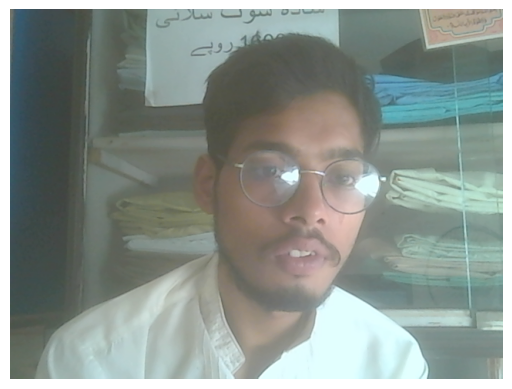

In [31]:
import cv2
import matplotlib.pyplot as plt
from IPython.display import display, clear_output

# Load Haar Cascade
face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')

# Open webcam
cap = cv2.VideoCapture(0)

for i in range(200):  # limit frames in notebooks to avoid infinite loop
    ret, frame = cap.read()
    if not ret:
        print("Error: Could not read frame.")
        break

    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    faces = face_cascade.detectMultiScale(gray, 1.1, 5)

    for (x, y, w, h) in faces:
        cv2.rectangle(frame, (x, y), (x+w, y+h), (255, 0, 0), 2)

    # Clear previous output
    clear_output(wait=True)

    # Convert BGR → RGB for matplotlib
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    plt.imshow(rgb)
    plt.axis("off")
    plt.show()

cap.release()


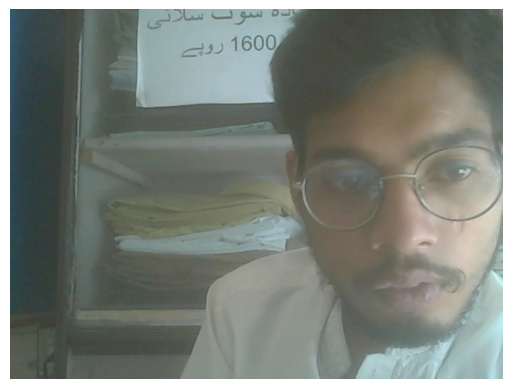

In [38]:
import cv2
import face_recognition
import matplotlib.pyplot as plt

# ------------------ STEP 1: Load Known Faces ------------------
# Load an image of a person you want to recognize
known_image = face_recognition.load_image_file(r"C:\Users\World\Documents\IMG20250316232757.jpg")
# Convert to face encoding (numerical representation of face features)
known_encoding = face_recognition.face_encodings(known_image)[0]

# Create a database of known people
known_faces = [known_encoding]
known_names = ["Person 1"]

# ------------------ STEP 2: Initialize Webcam ------------------
cap = cv2.VideoCapture(0)  # 0 = default webcam

while True:
    ret, frame = cap.read()
    if not ret:
        print("Error: Could not read frame.")
        break

    # Convert BGR (OpenCV format) → RGB (face_recognition format)
    rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    # ------------------ STEP 3: Detect Faces ------------------
    face_locations = face_recognition.face_locations(rgb_frame)
    # Returns list of (top, right, bottom, left) for each face

    # ------------------ STEP 4: Encode Faces ------------------
    face_encodings = face_recognition.face_encodings(rgb_frame, face_locations)

    # ------------------ STEP 5: Compare with Known Faces ------------------
    for (top, right, bottom, left), face_encoding in zip(face_locations, face_encodings):
        matches = face_recognition.compare_faces(known_faces, face_encoding)
        name = "Unknown"

        if True in matches:
            match_index = matches.index(True)
            name = known_names[match_index]

        # ------------------ STEP 6: Draw Bounding Box ------------------
        cv2.rectangle(frame, (left, top), (right, bottom), (0, 255, 0), 2)
        cv2.putText(frame, name, (left, top-10), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0,255,0), 2)

    # ------------------ STEP 7: Show Frame ------------------
    # For Jupyter/Colab → use matplotlib instead of cv2.imshow
    plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.show()
    break  # remove this if you want continuous webcam detection

cap.release()


In [36]:
import dlib
import face_recognition
import cv2

print("All packages loaded successfully!")


All packages loaded successfully!
